# Lab 3 - Zadanie

In [1]:
!pip install torch torchvision matplotlib

In [2]:
import zipfile
from collections import Counter

import matplotlib.pyplot as plt
import torch
from google.colab import files
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)
print("PyTorch:", torch.__version__)

PyTorch: 2.11.0+cpu


## 1. Zbiór danych

In [3]:
uploaded = files.upload()
zip_name = next(iter(uploaded))
with zipfile.ZipFile(zip_name) as z:
    z.extractall(".")
ROOT = "dane"

Saving dane_lab3.zip to dane_lab3.zip


## 2. Transformacje i wczytanie zbioru

In [4]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

eval_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
train_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_ds = datasets.ImageFolder(ROOT, transform=eval_tf)
train_ds = datasets.ImageFolder(ROOT, transform=train_tf)
eval_dl = DataLoader(eval_ds, batch_size=16, shuffle=False)
train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)

## 3. Statystyki zbioru

In [5]:
counts = Counter(eval_ds.targets)
print("Liczba klas:", len(eval_ds.classes))
for name, idx in eval_ds.class_to_idx.items():
    print(f"{name}: {counts[idx]} obrazów")
print("Razem:", len(eval_ds))
print("Rozmiar po transformacji:", tuple(eval_ds[0][0].shape))
print("class_to_idx:", eval_ds.class_to_idx)
print("To samo mapowanie w obu wariantach:",
      eval_ds.class_to_idx == train_ds.class_to_idx)

Liczba klas: 2
auto: 34 obrazów
motocykl: 34 obrazów
Razem: 68
Rozmiar po transformacji: (3, 128, 128)
class_to_idx: {'auto': 0, 'motocykl': 1}
To samo mapowanie w obu wariantach: True


## 4. Sprawdzenie paczki

Paczka ewaluacyjna: (16, 3, 128, 128) (16,)
Paczka treningowa: (16, 3, 128, 128) (16,)
Etykiety w paczce treningowej: [1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0]


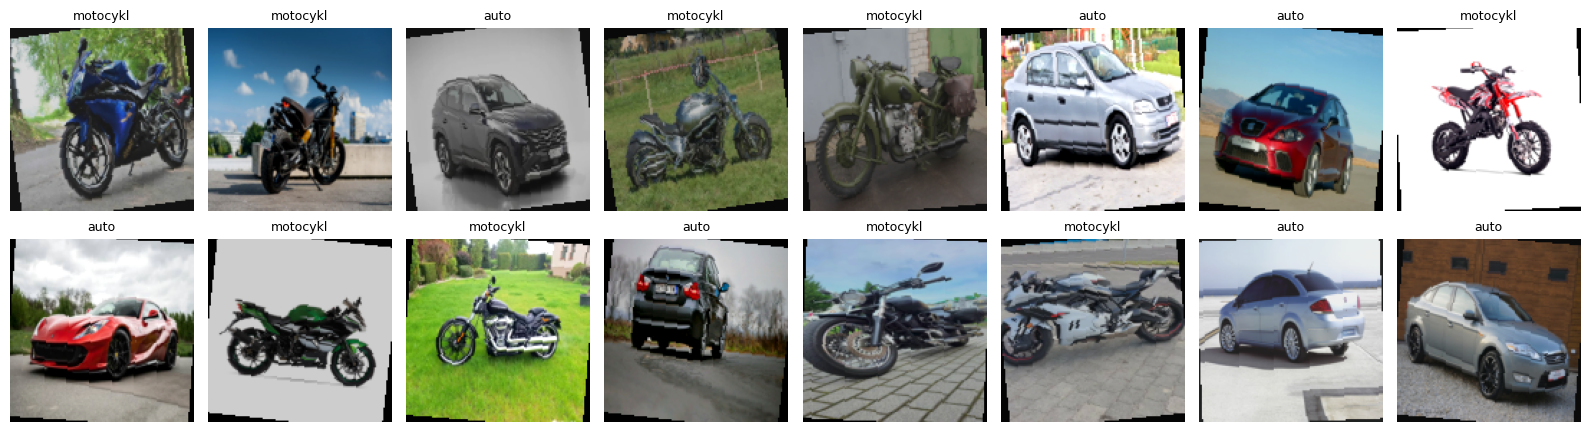

In [6]:
def denorm(img):
    img = img * torch.tensor(std).view(3, 1, 1)
    img = img + torch.tensor(mean).view(3, 1, 1)
    return img.clamp(0, 1).permute(1, 2, 0).numpy()


xe, ye = next(iter(eval_dl))
print("Paczka ewaluacyjna:", tuple(xe.shape), tuple(ye.shape))
xb, yb = next(iter(train_dl))
print("Paczka treningowa:", tuple(xb.shape), tuple(yb.shape))
print("Etykiety w paczce treningowej:", yb.tolist())

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, img, label in zip(axes.flat, xb, yb):
    ax.imshow(denorm(img))
    ax.set_title(train_ds.classes[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Podgląd augmentacji

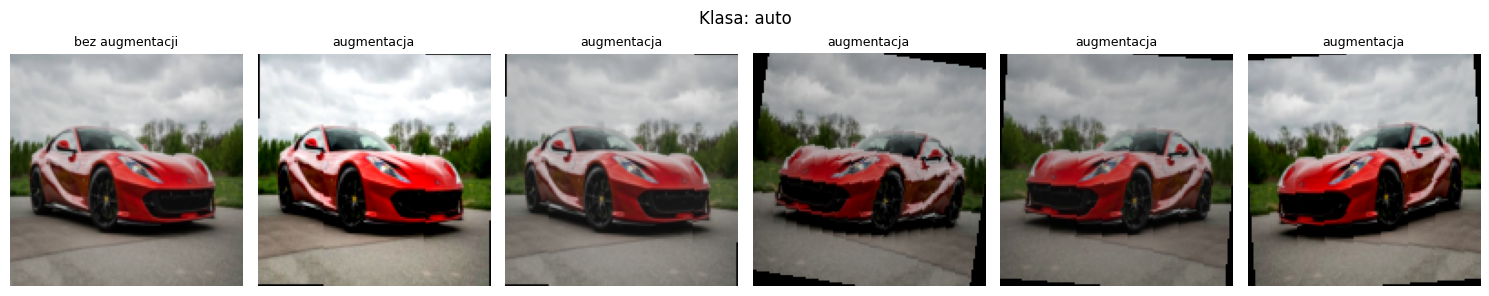

In [7]:
path, label = eval_ds.samples[0]
raw = Image.open(path).convert("RGB")

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(denorm(eval_tf(raw)))
axes[0].set_title("bez augmentacji", fontsize=9)
for ax in axes[1:]:
    ax.imshow(denorm(train_tf(raw)))
    ax.set_title("augmentacja", fontsize=9)
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Klasa: {eval_ds.classes[label]}")
plt.tight_layout()
plt.show()